In [9]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import optuna
from xgboost import XGBRegressor


df = pd.read_csv('data/solar_dataset_tauron.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp') #musi byc chronologicznie


kolumny_do_modelu = [c for c in df.columns if c not in ['timestamp', 'date', 'production_mwh']]
X = df[kolumny_do_modelu]
y = df['production_mwh']


Dane gotowe: X ma kształt (17544, 10), y ma kształt (17544,)


In [10]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
tscv = TimeSeriesSplit(n_splits=5, gap=24, test_size=24*30) #sprawdzay na 5 roznych odcinkach model bedzie mogl zagladac w przyszlosc o 30 dni do przodu, z 24 godzinna przerwa miedzy danymi tetowymi a treningowymi

#timeseries split eden z metod walidacji modelu dla danych w ktorych kolejnoc ma znaczenie (pogoda, produkcja)
#główna różnica jest taka że model nie zagląda w przyszlosc

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

pipeline = Pipeline([
    ('model', XGBRegressor(
        n_estimators=2000,
        early_stopping_rounds=50,
        eval_metric='mae',
        tree_method='hist',
        random_state=42
    ))
])

In [12]:
import optuna

def objective(trial):
    params = {
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'learning_rate':    trial.suggest_float('lr', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),
        'reg_alpha':        trial.suggest_float('alpha', 1e-3, 10, log=True),
        'reg_lambda':       trial.suggest_float('lambda', 0.01, 100, log=True),
    }
    # CV wewnątrz objective
    maes = []
    for tr_idx, te_idx in tscv.split(X):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

        model = XGBRegressor(**params, n_estimators=2000,
                             early_stopping_rounds=50,
                             eval_metric='mae', random_state=42)
        model.fit(X_tr, y_tr,
                  eval_set=[(X_te, y_te)], verbose=False)
        maes.append(mean_absolute_error(y_te, model.predict(X_te)))
    return np.mean(maes)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

[I 2026-04-15 18:52:57,750] A new study created in memory with name: no-name-c80c2aa9-bf64-44f9-99eb-803fd79b0c9e
Best trial: 0. Best value: 0.400113:   1%|          | 1/100 [00:02<04:51,  2.95s/it]

[I 2026-04-15 18:53:00,707] Trial 0 finished with value: 0.4001133405131566 and parameters: {'max_depth': 4, 'lr': 0.1266634163201092, 'subsample': 0.5052133605890068, 'colsample': 0.7791802656686373, 'min_child_weight': 13, 'alpha': 2.2182452118682967, 'lambda': 6.891992500872455}. Best is trial 0 with value: 0.4001133405131566.


Best trial: 1. Best value: 0.345704:   2%|▏         | 2/100 [00:05<04:46,  2.92s/it]

[I 2026-04-15 18:53:03,606] Trial 1 finished with value: 0.34570379240463167 and parameters: {'max_depth': 9, 'lr': 0.16891911913201949, 'subsample': 0.6656299778523522, 'colsample': 0.7452319734891444, 'min_child_weight': 12, 'alpha': 0.0010201954061733643, 'lambda': 0.753569939143283}. Best is trial 1 with value: 0.34570379240463167.


Best trial: 1. Best value: 0.345704:   3%|▎         | 3/100 [00:16<10:13,  6.32s/it]

[I 2026-04-15 18:53:13,974] Trial 2 finished with value: 0.4793825356410057 and parameters: {'max_depth': 3, 'lr': 0.011675573647286523, 'subsample': 0.6987181313172921, 'colsample': 0.7335987560578696, 'min_child_weight': 4, 'alpha': 2.5089657105273773, 'lambda': 0.3313909452231153}. Best is trial 1 with value: 0.34570379240463167.


Best trial: 1. Best value: 0.345704:   4%|▍         | 4/100 [00:21<09:15,  5.78s/it]

[I 2026-04-15 18:53:18,933] Trial 3 finished with value: 0.47626693378676793 and parameters: {'max_depth': 4, 'lr': 0.03140431930234402, 'subsample': 0.515337119616931, 'colsample': 0.5922011847235862, 'min_child_weight': 15, 'alpha': 1.479345649246654, 'lambda': 10.45587551893227}. Best is trial 1 with value: 0.34570379240463167.


Best trial: 4. Best value: 0.320171:   5%|▌         | 5/100 [00:27<09:19,  5.89s/it]

[I 2026-04-15 18:53:25,011] Trial 4 finished with value: 0.32017116809327495 and parameters: {'max_depth': 5, 'lr': 0.13384742667785676, 'subsample': 0.9588894504043904, 'colsample': 0.8481407246176854, 'min_child_weight': 10, 'alpha': 0.16854344003933372, 'lambda': 56.6288512628085}. Best is trial 4 with value: 0.32017116809327495.


Best trial: 4. Best value: 0.320171:   6%|▌         | 6/100 [00:37<11:18,  7.22s/it]

[I 2026-04-15 18:53:34,819] Trial 5 finished with value: 0.3345929357660754 and parameters: {'max_depth': 8, 'lr': 0.030522935988146895, 'subsample': 0.6031862702928015, 'colsample': 0.6390354919297009, 'min_child_weight': 19, 'alpha': 1.5857586659265095, 'lambda': 23.24996331225633}. Best is trial 4 with value: 0.32017116809327495.


Best trial: 4. Best value: 0.320171:   7%|▋         | 7/100 [00:43<10:46,  6.96s/it]

[I 2026-04-15 18:53:41,227] Trial 6 finished with value: 0.4814475555965497 and parameters: {'max_depth': 7, 'lr': 0.13905228147432755, 'subsample': 0.6114171879200679, 'colsample': 0.5668995481526693, 'min_child_weight': 5, 'alpha': 1.5545870351038737, 'lambda': 5.23978311134505}. Best is trial 4 with value: 0.32017116809327495.


Best trial: 4. Best value: 0.320171:   8%|▊         | 8/100 [00:57<14:11,  9.25s/it]

[I 2026-04-15 18:53:55,401] Trial 7 finished with value: 0.39787431766761444 and parameters: {'max_depth': 5, 'lr': 0.010307687903746447, 'subsample': 0.744158167142907, 'colsample': 0.5652614313503805, 'min_child_weight': 18, 'alpha': 0.3036710347986845, 'lambda': 21.96150046969157}. Best is trial 4 with value: 0.32017116809327495.


Best trial: 4. Best value: 0.320171:   9%|▉         | 9/100 [01:04<12:40,  8.36s/it]

[I 2026-04-15 18:54:01,802] Trial 8 finished with value: 0.4085458116155219 and parameters: {'max_depth': 6, 'lr': 0.2593857082052169, 'subsample': 0.8328855590332485, 'colsample': 0.6062717356891187, 'min_child_weight': 5, 'alpha': 0.24214888283887354, 'lambda': 20.77708509018618}. Best is trial 4 with value: 0.32017116809327495.


Best trial: 9. Best value: 0.315308:  10%|█         | 10/100 [01:11<11:55,  7.95s/it]

[I 2026-04-15 18:54:08,829] Trial 9 finished with value: 0.3153075380175074 and parameters: {'max_depth': 6, 'lr': 0.01613665550424093, 'subsample': 0.8588839125822216, 'colsample': 0.8960907924905004, 'min_child_weight': 13, 'alpha': 0.04994547815117801, 'lambda': 5.223556145455365}. Best is trial 9 with value: 0.3153075380175074.


Best trial: 9. Best value: 0.315308:  11%|█         | 11/100 [01:21<13:02,  8.79s/it]

[I 2026-04-15 18:54:19,539] Trial 10 finished with value: 0.3343841042418426 and parameters: {'max_depth': 10, 'lr': 0.02095403097184182, 'subsample': 0.8616089675996029, 'colsample': 0.9845296080747297, 'min_child_weight': 8, 'alpha': 0.011694519722808484, 'lambda': 0.0215472226350759}. Best is trial 9 with value: 0.3153075380175074.


Best trial: 11. Best value: 0.292211:  12%|█▏        | 12/100 [01:28<11:46,  8.03s/it]

[I 2026-04-15 18:54:25,822] Trial 11 finished with value: 0.2922113207321543 and parameters: {'max_depth': 6, 'lr': 0.07124903194953802, 'subsample': 0.9765584839090105, 'colsample': 0.9078969304765233, 'min_child_weight': 9, 'alpha': 0.02987063880122541, 'lambda': 88.94786683493474}. Best is trial 11 with value: 0.2922113207321543.


Best trial: 12. Best value: 0.272849:  13%|█▎        | 13/100 [01:37<12:22,  8.54s/it]

[I 2026-04-15 18:54:35,531] Trial 12 finished with value: 0.27284859256173577 and parameters: {'max_depth': 7, 'lr': 0.06311501225476962, 'subsample': 0.9931632798026233, 'colsample': 0.9655008281733787, 'min_child_weight': 9, 'alpha': 0.023959130971965642, 'lambda': 91.43509783845872}. Best is trial 12 with value: 0.27284859256173577.


Best trial: 12. Best value: 0.272849:  14%|█▍        | 14/100 [01:43<10:50,  7.56s/it]

[I 2026-04-15 18:54:40,826] Trial 13 finished with value: 0.29938590493859485 and parameters: {'max_depth': 8, 'lr': 0.05813826228508848, 'subsample': 0.9981505336491721, 'colsample': 0.9958510950558196, 'min_child_weight': 1, 'alpha': 0.013989906648474687, 'lambda': 96.53822527971029}. Best is trial 12 with value: 0.27284859256173577.


Best trial: 14. Best value: 0.260404:  15%|█▌        | 15/100 [01:58<14:16, 10.08s/it]

[I 2026-04-15 18:54:56,733] Trial 14 finished with value: 0.2604044458349474 and parameters: {'max_depth': 7, 'lr': 0.0646699733274902, 'subsample': 0.9370603116031603, 'colsample': 0.9143408088350844, 'min_child_weight': 8, 'alpha': 0.00489550448049527, 'lambda': 98.10717781717665}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  16%|█▌        | 16/100 [02:02<11:09,  7.96s/it]

[I 2026-04-15 18:54:59,796] Trial 15 finished with value: 0.33520915547566543 and parameters: {'max_depth': 8, 'lr': 0.08285924423821565, 'subsample': 0.9055394695705978, 'colsample': 0.9317152664495629, 'min_child_weight': 8, 'alpha': 0.002658670528068635, 'lambda': 0.07646192803985509}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  17%|█▋        | 17/100 [02:06<09:28,  6.85s/it]

[I 2026-04-15 18:55:04,067] Trial 16 finished with value: 0.3186190169346509 and parameters: {'max_depth': 7, 'lr': 0.040292465535111906, 'subsample': 0.9134646158437576, 'colsample': 0.8230025114282761, 'min_child_weight': 7, 'alpha': 0.004514430762362046, 'lambda': 1.8680053568008477}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  18%|█▊        | 18/100 [02:12<09:17,  6.80s/it]

[I 2026-04-15 18:55:10,729] Trial 17 finished with value: 0.42133140135222746 and parameters: {'max_depth': 10, 'lr': 0.09195094427921724, 'subsample': 0.7942204256638885, 'colsample': 0.6806949218766452, 'min_child_weight': 16, 'alpha': 0.004856771293692369, 'lambda': 1.6865123111850635}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  19%|█▉        | 19/100 [02:37<16:23, 12.14s/it]

[I 2026-04-15 18:55:35,325] Trial 18 finished with value: 0.2673381794922001 and parameters: {'max_depth': 9, 'lr': 0.04833221991710026, 'subsample': 0.9271402943443728, 'colsample': 0.9435541814824626, 'min_child_weight': 1, 'alpha': 0.06649504625654595, 'lambda': 37.11164314093059}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  20%|██        | 20/100 [02:52<17:12, 12.90s/it]

[I 2026-04-15 18:55:49,997] Trial 19 finished with value: 0.33515046129698994 and parameters: {'max_depth': 9, 'lr': 0.04302808109607252, 'subsample': 0.9200548175103324, 'colsample': 0.853515547064122, 'min_child_weight': 1, 'alpha': 0.0906975539605458, 'lambda': 0.31282513047674865}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  21%|██        | 21/100 [03:08<18:10, 13.80s/it]

[I 2026-04-15 18:56:05,888] Trial 20 finished with value: 0.27358950322625597 and parameters: {'max_depth': 9, 'lr': 0.02466284055684859, 'subsample': 0.7860844459646686, 'colsample': 0.8108566367184462, 'min_child_weight': 3, 'alpha': 0.5171736222973292, 'lambda': 26.6544602762377}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  22%|██▏       | 22/100 [03:19<16:50, 12.95s/it]

[I 2026-04-15 18:56:16,861] Trial 21 finished with value: 0.3995547103561378 and parameters: {'max_depth': 7, 'lr': 0.05329791673448029, 'subsample': 0.9479563245445881, 'colsample': 0.5045116455380229, 'min_child_weight': 6, 'alpha': 0.023035629278050453, 'lambda': 39.183359436662386}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  23%|██▎       | 23/100 [03:26<14:33, 11.34s/it]

[I 2026-04-15 18:56:24,458] Trial 22 finished with value: 0.2691830773684147 and parameters: {'max_depth': 8, 'lr': 0.05852048561294958, 'subsample': 0.9983235351429185, 'colsample': 0.9459977564948778, 'min_child_weight': 11, 'alpha': 0.06311089379351907, 'lambda': 87.12443073236864}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  24%|██▍       | 24/100 [03:30<11:22,  8.98s/it]

[I 2026-04-15 18:56:27,915] Trial 23 finished with value: 0.29523893240234417 and parameters: {'max_depth': 8, 'lr': 0.0969404733288239, 'subsample': 0.8792127207672729, 'colsample': 0.9407793318095157, 'min_child_weight': 11, 'alpha': 0.07691339072154132, 'lambda': 11.222730095825673}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 14. Best value: 0.260404:  25%|██▌       | 25/100 [03:40<11:49,  9.46s/it]

[I 2026-04-15 18:56:38,498] Trial 24 finished with value: 0.2688819571348811 and parameters: {'max_depth': 9, 'lr': 0.04599412898055079, 'subsample': 0.9382303125233032, 'colsample': 0.8822905005670093, 'min_child_weight': 15, 'alpha': 0.5665193415200652, 'lambda': 43.189282079438364}. Best is trial 14 with value: 0.2604044458349474.


Best trial: 25. Best value: 0.259047:  26%|██▌       | 26/100 [04:05<17:16, 14.00s/it]

[I 2026-04-15 18:57:03,102] Trial 25 finished with value: 0.25904655358431405 and parameters: {'max_depth': 10, 'lr': 0.04298367660702484, 'subsample': 0.8097592869180096, 'colsample': 0.9077536292797256, 'min_child_weight': 17, 'alpha': 5.887442179431928, 'lambda': 44.519397152621416}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  27%|██▋       | 27/100 [04:12<14:38, 12.03s/it]

[I 2026-04-15 18:57:10,542] Trial 26 finished with value: 0.2845135043642958 and parameters: {'max_depth': 10, 'lr': 0.034079713027478295, 'subsample': 0.8034179770137637, 'colsample': 0.8719296366633258, 'min_child_weight': 20, 'alpha': 0.0019534053207293203, 'lambda': 14.306330942174677}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  28%|██▊       | 28/100 [04:29<16:08, 13.45s/it]

[I 2026-04-15 18:57:27,280] Trial 27 finished with value: 0.29707076627793594 and parameters: {'max_depth': 10, 'lr': 0.01964050568005853, 'subsample': 0.7576209054226459, 'colsample': 0.9109976142888534, 'min_child_weight': 2, 'alpha': 0.009014294453787248, 'lambda': 2.688506705373592}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  29%|██▉       | 29/100 [04:48<17:44, 14.99s/it]

[I 2026-04-15 18:57:45,873] Trial 28 finished with value: 0.2742907751523932 and parameters: {'max_depth': 9, 'lr': 0.07881250115068542, 'subsample': 0.8291898582030138, 'colsample': 0.795758837333014, 'min_child_weight': 16, 'alpha': 7.222398957361053, 'lambda': 50.71239135085553}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  30%|███       | 30/100 [05:03<17:32, 15.03s/it]

[I 2026-04-15 18:58:00,999] Trial 29 finished with value: 0.29813714908679784 and parameters: {'max_depth': 10, 'lr': 0.100641480200825, 'subsample': 0.8832882587757691, 'colsample': 0.7638181630123564, 'min_child_weight': 14, 'alpha': 8.99530091877723, 'lambda': 5.3600746124732375}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  31%|███       | 31/100 [05:16<16:49, 14.63s/it]

[I 2026-04-15 18:58:14,698] Trial 30 finished with value: 0.2777795814951467 and parameters: {'max_depth': 9, 'lr': 0.03665887999553209, 'subsample': 0.729562889403797, 'colsample': 0.833395370567708, 'min_child_weight': 18, 'alpha': 4.033588056841611, 'lambda': 39.258324530832375}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  32%|███▏      | 32/100 [05:21<13:11, 11.63s/it]

[I 2026-04-15 18:58:19,338] Trial 31 finished with value: 0.27625496524319854 and parameters: {'max_depth': 9, 'lr': 0.046554755097194096, 'subsample': 0.9304061213543038, 'colsample': 0.8842204715119835, 'min_child_weight': 17, 'alpha': 0.5898213993187007, 'lambda': 34.25717197226202}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 25. Best value: 0.259047:  33%|███▎      | 33/100 [05:26<10:36,  9.51s/it]

[I 2026-04-15 18:58:23,883] Trial 32 finished with value: 0.2897891062858554 and parameters: {'max_depth': 9, 'lr': 0.049978390992293176, 'subsample': 0.9441137042599846, 'colsample': 0.9652867111916674, 'min_child_weight': 14, 'alpha': 0.7884016158993318, 'lambda': 10.680554490601125}. Best is trial 25 with value: 0.25904655358431405.


Best trial: 33. Best value: 0.250315:  34%|███▍      | 34/100 [10:15<1:42:40, 93.35s/it]

[I 2026-04-15 19:03:12,851] Trial 33 finished with value: 0.2503154214061387 and parameters: {'max_depth': 10, 'lr': 0.02796394057014919, 'subsample': 0.8905410548476056, 'colsample': 0.9288836653838929, 'min_child_weight': 13, 'alpha': 3.9135474477736643, 'lambda': 60.863591230554725}. Best is trial 33 with value: 0.2503154214061387.


Best trial: 34. Best value: 0.247999:  35%|███▌      | 35/100 [10:43<1:20:07, 73.97s/it]

[I 2026-04-15 19:03:41,604] Trial 34 finished with value: 0.2479992531664977 and parameters: {'max_depth': 10, 'lr': 0.026433825151643872, 'subsample': 0.8387033010448489, 'colsample': 0.9237944120154742, 'min_child_weight': 12, 'alpha': 3.714178284343117, 'lambda': 56.11407025004355}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  36%|███▌      | 36/100 [10:58<1:00:03, 56.30s/it]

[I 2026-04-15 19:03:56,679] Trial 35 finished with value: 0.2949593646263325 and parameters: {'max_depth': 10, 'lr': 0.02615113422522501, 'subsample': 0.8333632268401165, 'colsample': 0.7286769634001117, 'min_child_weight': 12, 'alpha': 3.8576833582399437, 'lambda': 15.45602570133412}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  37%|███▋      | 37/100 [11:04<42:59, 40.95s/it]  

[I 2026-04-15 19:04:01,818] Trial 36 finished with value: 0.4902231826160614 and parameters: {'max_depth': 3, 'lr': 0.02875573771280382, 'subsample': 0.889670206633828, 'colsample': 0.9188211113161387, 'min_child_weight': 12, 'alpha': 3.0378374623519107, 'lambda': 59.21455695661027}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  38%|███▊      | 38/100 [11:10<31:32, 30.52s/it]

[I 2026-04-15 19:04:08,014] Trial 37 finished with value: 0.33706208301110563 and parameters: {'max_depth': 5, 'lr': 0.016749827027217036, 'subsample': 0.7063652935025976, 'colsample': 0.8633639974390235, 'min_child_weight': 10, 'alpha': 6.7334392680929565, 'lambda': 0.8345007310758438}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  39%|███▉      | 39/100 [11:24<26:01, 25.59s/it]

[I 2026-04-15 19:04:22,101] Trial 38 finished with value: 0.3842636089249547 and parameters: {'max_depth': 4, 'lr': 0.012752072680274862, 'subsample': 0.7759908744686173, 'colsample': 0.9688694458557672, 'min_child_weight': 13, 'alpha': 1.1157566329443724, 'lambda': 7.302091731085112}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  40%|████      | 40/100 [11:42<23:24, 23.41s/it]

[I 2026-04-15 19:04:40,402] Trial 39 finished with value: 0.2658738681576068 and parameters: {'max_depth': 10, 'lr': 0.022982514640478034, 'subsample': 0.8156089960395254, 'colsample': 0.7079790051025716, 'min_child_weight': 14, 'alpha': 2.1097992336606084, 'lambda': 57.444624914102825}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  41%|████      | 41/100 [12:01<21:40, 22.04s/it]

[I 2026-04-15 19:04:59,249] Trial 40 finished with value: 0.2915256804306937 and parameters: {'max_depth': 10, 'lr': 0.01659609409730829, 'subsample': 0.6666892659508339, 'colsample': 0.7860261880667224, 'min_child_weight': 20, 'alpha': 4.9730793311715615, 'lambda': 0.5011651109279665}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  42%|████▏     | 42/100 [12:27<22:29, 23.27s/it]

[I 2026-04-15 19:05:25,379] Trial 41 finished with value: 0.283253703160955 and parameters: {'max_depth': 10, 'lr': 0.0226219242010718, 'subsample': 0.8142859756147578, 'colsample': 0.6614482838171327, 'min_child_weight': 14, 'alpha': 1.8997522618714842, 'lambda': 66.73107892980248}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  43%|████▎     | 43/100 [12:48<21:33, 22.69s/it]

[I 2026-04-15 19:05:46,715] Trial 42 finished with value: 0.3243351114597535 and parameters: {'max_depth': 10, 'lr': 0.03221370865457105, 'subsample': 0.8496162856551747, 'colsample': 0.6988051324307049, 'min_child_weight': 15, 'alpha': 2.3176509269872496, 'lambda': 22.839315178109757}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  44%|████▍     | 44/100 [13:02<18:31, 19.84s/it]

[I 2026-04-15 19:05:59,917] Trial 43 finished with value: 0.2793424992679049 and parameters: {'max_depth': 10, 'lr': 0.02832478459062789, 'subsample': 0.8597616956839798, 'colsample': 0.7353826917596357, 'min_child_weight': 16, 'alpha': 1.0125003443495006, 'lambda': 55.58011283455779}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  45%|████▌     | 45/100 [13:09<14:46, 16.12s/it]

[I 2026-04-15 19:06:07,352] Trial 44 finished with value: 0.42699276901682015 and parameters: {'max_depth': 3, 'lr': 0.03645759159255988, 'subsample': 0.7735257891241952, 'colsample': 0.8987798511438688, 'min_child_weight': 10, 'alpha': 9.411634256042833, 'lambda': 17.74190820384712}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  46%|████▌     | 46/100 [13:19<12:56, 14.38s/it]

[I 2026-04-15 19:06:17,660] Trial 45 finished with value: 0.3046417030278831 and parameters: {'max_depth': 9, 'lr': 0.17348439852427047, 'subsample': 0.8232980459446206, 'colsample': 0.84011564440696, 'min_child_weight': 12, 'alpha': 2.6369754234459144, 'lambda': 28.52442511541296}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  47%|████▋     | 47/100 [13:34<12:37, 14.30s/it]

[I 2026-04-15 19:06:31,782] Trial 46 finished with value: 0.2751595094115819 and parameters: {'max_depth': 10, 'lr': 0.01974010276720638, 'subsample': 0.9653342627574232, 'colsample': 0.7076526995707899, 'min_child_weight': 18, 'alpha': 0.15400166136198992, 'lambda': 63.98617505501284}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  48%|████▊     | 48/100 [13:44<11:28, 13.24s/it]

[I 2026-04-15 19:06:42,544] Trial 47 finished with value: 0.3154843817431191 and parameters: {'max_depth': 8, 'lr': 0.06582602340012343, 'subsample': 0.8915850737069494, 'colsample': 0.7622448935760489, 'min_child_weight': 9, 'alpha': 5.228083473318484, 'lambda': 0.07698505300769011}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  49%|████▉     | 49/100 [14:03<12:44, 14.99s/it]

[I 2026-04-15 19:07:01,610] Trial 48 finished with value: 0.29083787467533656 and parameters: {'max_depth': 6, 'lr': 0.015057394147320002, 'subsample': 0.5076496027458288, 'colsample': 0.9836059355535781, 'min_child_weight': 13, 'alpha': 0.3135562624200191, 'lambda': 96.48575134912583}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  50%|█████     | 50/100 [14:22<13:30, 16.20s/it]

[I 2026-04-15 19:07:20,650] Trial 49 finished with value: 0.3201333401975991 and parameters: {'max_depth': 10, 'lr': 0.023301155360034572, 'subsample': 0.5590393147942014, 'colsample': 0.6359767363539899, 'min_child_weight': 17, 'alpha': 1.3905954277681687, 'lambda': 8.486342031699788}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  51%|█████     | 51/100 [14:34<12:07, 14.84s/it]

[I 2026-04-15 19:07:32,314] Trial 50 finished with value: 0.3254252904429313 and parameters: {'max_depth': 5, 'lr': 0.040237546041543955, 'subsample': 0.850325477519237, 'colsample': 0.9215610113248598, 'min_child_weight': 8, 'alpha': 3.1511612161434703, 'lambda': 2.9032864336965307}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  52%|█████▏    | 52/100 [14:57<13:48, 17.27s/it]

[I 2026-04-15 19:07:55,238] Trial 51 finished with value: 0.2563775257591438 and parameters: {'max_depth': 9, 'lr': 0.03057165331961239, 'subsample': 0.902473632295629, 'colsample': 0.9492020482535001, 'min_child_weight': 4, 'alpha': 0.046347015234080774, 'lambda': 25.606283896067886}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  53%|█████▎    | 53/100 [15:25<16:08, 20.60s/it]

[I 2026-04-15 19:08:23,628] Trial 52 finished with value: 0.26004491419974074 and parameters: {'max_depth': 10, 'lr': 0.027920541163308145, 'subsample': 0.9031098535202979, 'colsample': 0.9572291582676367, 'min_child_weight': 4, 'alpha': 0.03286273493520706, 'lambda': 27.161131828805537}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  54%|█████▍    | 54/100 [15:53<17:27, 22.77s/it]

[I 2026-04-15 19:08:51,462] Trial 53 finished with value: 0.2558793998481321 and parameters: {'max_depth': 10, 'lr': 0.02959651941231185, 'subsample': 0.9019353261341737, 'colsample': 0.9976105844029864, 'min_child_weight': 4, 'alpha': 0.038745670868273914, 'lambda': 27.83504082991371}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  55%|█████▌    | 55/100 [16:21<18:05, 24.13s/it]

[I 2026-04-15 19:09:18,762] Trial 54 finished with value: 0.261365742492643 and parameters: {'max_depth': 10, 'lr': 0.02979376116868777, 'subsample': 0.9050441961261105, 'colsample': 0.9953613412456537, 'min_child_weight': 4, 'alpha': 0.03634398654335291, 'lambda': 21.37235804886304}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  56%|█████▌    | 56/100 [16:44<17:34, 23.97s/it]

[I 2026-04-15 19:09:42,371] Trial 55 finished with value: 0.2574862322446154 and parameters: {'max_depth': 9, 'lr': 0.026575324053068835, 'subsample': 0.86767966925892, 'colsample': 0.9596392410955997, 'min_child_weight': 4, 'alpha': 0.11954715015116552, 'lambda': 29.381874697276878}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  57%|█████▋    | 57/100 [17:40<24:01, 33.52s/it]

[I 2026-04-15 19:10:38,151] Trial 56 finished with value: 0.28262597638350867 and parameters: {'max_depth': 9, 'lr': 0.037806554461693315, 'subsample': 0.8700451845183409, 'colsample': 0.977030693626509, 'min_child_weight': 6, 'alpha': 0.22412421748220962, 'lambda': 12.420315347864326}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  58%|█████▊    | 58/100 [17:55<19:40, 28.11s/it]

[I 2026-04-15 19:10:53,631] Trial 57 finished with value: 0.26799412076520784 and parameters: {'max_depth': 9, 'lr': 0.03287751697772476, 'subsample': 0.8425376245297527, 'colsample': 0.9338990959842183, 'min_child_weight': 5, 'alpha': 0.017080486982142682, 'lambda': 32.69279690688939}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  59%|█████▉    | 59/100 [18:20<18:33, 27.17s/it]

[I 2026-04-15 19:11:18,618] Trial 58 finished with value: 0.28150333602890776 and parameters: {'max_depth': 8, 'lr': 0.018794280375869603, 'subsample': 0.8604203384995366, 'colsample': 0.9578938633152597, 'min_child_weight': 3, 'alpha': 0.12053926886176301, 'lambda': 16.609904669439498}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  60%|██████    | 60/100 [18:26<13:47, 20.69s/it]

[I 2026-04-15 19:11:24,190] Trial 59 finished with value: 0.296720842616801 and parameters: {'max_depth': 9, 'lr': 0.042201205591909915, 'subsample': 0.9707984487365613, 'colsample': 0.9980686850060958, 'min_child_weight': 6, 'alpha': 0.054470113407752534, 'lambda': 4.158557893938106}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  61%|██████    | 61/100 [18:42<12:27, 19.16s/it]

[I 2026-04-15 19:11:39,766] Trial 60 finished with value: 0.2775275835565158 and parameters: {'max_depth': 8, 'lr': 0.0259963254549135, 'subsample': 0.8770924036572841, 'colsample': 0.893335039212584, 'min_child_weight': 2, 'alpha': 0.00828647076498414, 'lambda': 76.36998816672372}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  62%|██████▏   | 62/100 [19:11<14:03, 22.19s/it]

[I 2026-04-15 19:12:09,035] Trial 61 finished with value: 0.258883074121362 and parameters: {'max_depth': 10, 'lr': 0.026630323369042218, 'subsample': 0.9007278187008492, 'colsample': 0.9551375091619472, 'min_child_weight': 4, 'alpha': 0.039153642157808935, 'lambda': 30.962117484640775}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  63%|██████▎   | 63/100 [19:40<15:04, 24.44s/it]

[I 2026-04-15 19:12:38,728] Trial 62 finished with value: 0.26085768707702695 and parameters: {'max_depth': 10, 'lr': 0.03211318886575482, 'subsample': 0.9180594129044065, 'colsample': 0.9453684336405723, 'min_child_weight': 3, 'alpha': 0.022689723759130233, 'lambda': 44.57703929203035}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  64%|██████▍   | 64/100 [20:07<15:00, 25.00s/it]

[I 2026-04-15 19:13:05,049] Trial 63 finished with value: 0.25600155392301016 and parameters: {'max_depth': 9, 'lr': 0.022196069946125895, 'subsample': 0.9044747294273235, 'colsample': 0.9318177601533146, 'min_child_weight': 4, 'alpha': 0.10500405990752149, 'lambda': 22.15442493380459}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  65%|██████▌   | 65/100 [20:30<14:19, 24.56s/it]

[I 2026-04-15 19:13:28,574] Trial 64 finished with value: 0.262387362421925 and parameters: {'max_depth': 9, 'lr': 0.014254065421654012, 'subsample': 0.8941077815466888, 'colsample': 0.929896163108967, 'min_child_weight': 4, 'alpha': 0.04081011398336334, 'lambda': 25.037668488972862}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  66%|██████▌   | 66/100 [20:44<12:04, 21.32s/it]

[I 2026-04-15 19:13:42,335] Trial 65 finished with value: 0.28412259108944676 and parameters: {'max_depth': 9, 'lr': 0.018197855515840175, 'subsample': 0.9538322324747984, 'colsample': 0.9524563455482876, 'min_child_weight': 5, 'alpha': 0.09459512039720833, 'lambda': 8.690230067868734}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  67%|██████▋   | 67/100 [21:32<16:07, 29.33s/it]

[I 2026-04-15 19:14:30,363] Trial 66 finished with value: 0.26204511179890966 and parameters: {'max_depth': 9, 'lr': 0.022568040871513862, 'subsample': 0.9212929638195646, 'colsample': 0.9727556582573865, 'min_child_weight': 7, 'alpha': 0.1281317914395321, 'lambda': 20.133835743869348}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  68%|██████▊   | 68/100 [22:00<15:26, 28.97s/it]

[I 2026-04-15 19:14:58,471] Trial 67 finished with value: 0.26475860627926523 and parameters: {'max_depth': 9, 'lr': 0.024971456350037186, 'subsample': 0.8702850624591191, 'colsample': 0.9796510180137211, 'min_child_weight': 2, 'alpha': 0.04900768981832358, 'lambda': 33.07606773499179}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  69%|██████▉   | 69/100 [22:12<12:22, 23.95s/it]

[I 2026-04-15 19:15:10,724] Trial 68 finished with value: 0.32508716908481333 and parameters: {'max_depth': 8, 'lr': 0.02129546724722494, 'subsample': 0.9856180223203478, 'colsample': 0.8713493035604964, 'min_child_weight': 3, 'alpha': 0.23087689599445516, 'lambda': 0.1707741254944638}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  70%|███████   | 70/100 [22:40<12:29, 24.97s/it]

[I 2026-04-15 19:15:38,075] Trial 69 finished with value: 0.2702942139038842 and parameters: {'max_depth': 10, 'lr': 0.011935772324790131, 'subsample': 0.9312410406443503, 'colsample': 0.9306906353136255, 'min_child_weight': 4, 'alpha': 0.3631605312115399, 'lambda': 15.46400911994724}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  71%|███████   | 71/100 [22:49<09:46, 20.21s/it]

[I 2026-04-15 19:15:47,175] Trial 70 finished with value: 0.3478739386038769 and parameters: {'max_depth': 10, 'lr': 0.026827059634208127, 'subsample': 0.9538893754412188, 'colsample': 0.9986642097967524, 'min_child_weight': 5, 'alpha': 0.02669661569025519, 'lambda': 0.023667244427077752}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 34. Best value: 0.247999:  72%|███████▏  | 72/100 [23:18<10:38, 22.80s/it]

[I 2026-04-15 19:16:16,028] Trial 71 finished with value: 0.24809638563235142 and parameters: {'max_depth': 10, 'lr': 0.03612790212827369, 'subsample': 0.8000840408398515, 'colsample': 0.9068769967164416, 'min_child_weight': 6, 'alpha': 0.07545761370269832, 'lambda': 44.55599462781064}. Best is trial 34 with value: 0.2479992531664977.


Best trial: 72. Best value: 0.242312:  73%|███████▎  | 73/100 [23:45<10:55, 24.26s/it]

[I 2026-04-15 19:16:43,689] Trial 72 finished with value: 0.24231243567246627 and parameters: {'max_depth': 10, 'lr': 0.035688178805043075, 'subsample': 0.8374419107048952, 'colsample': 0.9034442308965726, 'min_child_weight': 6, 'alpha': 0.0788125739668364, 'lambda': 49.23400517222709}. Best is trial 72 with value: 0.24231243567246627.


Best trial: 73. Best value: 0.239198:  74%|███████▍  | 74/100 [26:18<27:08, 62.62s/it]

[I 2026-04-15 19:19:15,801] Trial 73 finished with value: 0.23919821347435724 and parameters: {'max_depth': 10, 'lr': 0.03484853120431638, 'subsample': 0.8321572431213095, 'colsample': 0.9012010766732409, 'min_child_weight': 6, 'alpha': 0.07114953729646493, 'lambda': 75.2034967943033}. Best is trial 73 with value: 0.23919821347435724.


Best trial: 74. Best value: 0.236827:  75%|███████▌  | 75/100 [26:43<21:26, 51.47s/it]

[I 2026-04-15 19:19:41,253] Trial 74 finished with value: 0.23682692142806783 and parameters: {'max_depth': 10, 'lr': 0.03503660095555571, 'subsample': 0.7991909206913341, 'colsample': 0.9033877960176802, 'min_child_weight': 7, 'alpha': 0.06712159155757096, 'lambda': 70.10957173010077}. Best is trial 74 with value: 0.23682692142806783.


Best trial: 74. Best value: 0.236827:  76%|███████▌  | 76/100 [27:12<17:54, 44.76s/it]

[I 2026-04-15 19:20:10,353] Trial 75 finished with value: 0.24244827390874096 and parameters: {'max_depth': 10, 'lr': 0.03552984617586201, 'subsample': 0.7879635349122897, 'colsample': 0.8544976549911628, 'min_child_weight': 7, 'alpha': 0.07805005139401819, 'lambda': 76.98854622294034}. Best is trial 74 with value: 0.23682692142806783.


Best trial: 74. Best value: 0.236827:  77%|███████▋  | 77/100 [27:33<14:23, 37.56s/it]

[I 2026-04-15 19:20:31,136] Trial 76 finished with value: 0.24922412732388852 and parameters: {'max_depth': 10, 'lr': 0.035031133270180675, 'subsample': 0.7981872185357223, 'colsample': 0.8576959537684422, 'min_child_weight': 7, 'alpha': 0.07166433019815821, 'lambda': 75.45354494923201}. Best is trial 74 with value: 0.23682692142806783.


Best trial: 74. Best value: 0.236827:  78%|███████▊  | 78/100 [28:02<12:51, 35.07s/it]

[I 2026-04-15 19:21:00,401] Trial 77 finished with value: 0.2408552286728026 and parameters: {'max_depth': 10, 'lr': 0.03655565877132603, 'subsample': 0.7464923778673509, 'colsample': 0.8615743744500839, 'min_child_weight': 7, 'alpha': 0.07375051958865066, 'lambda': 71.93695943072784}. Best is trial 74 with value: 0.23682692142806783.


Best trial: 78. Best value: 0.234948:  79%|███████▉  | 79/100 [28:26<11:08, 31.85s/it]

[I 2026-04-15 19:21:24,720] Trial 78 finished with value: 0.23494822250293695 and parameters: {'max_depth': 10, 'lr': 0.05322388888598878, 'subsample': 0.7470669543690428, 'colsample': 0.8134957602040103, 'min_child_weight': 7, 'alpha': 0.07559679305038224, 'lambda': 75.7962576198485}. Best is trial 78 with value: 0.23494822250293695.


Best trial: 79. Best value: 0.234894:  80%|████████  | 80/100 [28:52<10:00, 30.01s/it]

[I 2026-04-15 19:21:50,453] Trial 79 finished with value: 0.23489406597259227 and parameters: {'max_depth': 10, 'lr': 0.052744576209055656, 'subsample': 0.7624963915830739, 'colsample': 0.8238297327393689, 'min_child_weight': 8, 'alpha': 0.1526319834704211, 'lambda': 99.17262422836382}. Best is trial 79 with value: 0.23489406597259227.


Best trial: 80. Best value: 0.230484:  81%|████████  | 81/100 [29:18<09:04, 28.67s/it]

[I 2026-04-15 19:22:15,994] Trial 80 finished with value: 0.23048432379638406 and parameters: {'max_depth': 10, 'lr': 0.052336880487203134, 'subsample': 0.7341619914285586, 'colsample': 0.8039852287396958, 'min_child_weight': 7, 'alpha': 0.14809215409313312, 'lambda': 99.31137915281643}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  82%|████████▏ | 82/100 [29:42<08:14, 27.50s/it]

[I 2026-04-15 19:22:40,745] Trial 81 finished with value: 0.23368729675429742 and parameters: {'max_depth': 10, 'lr': 0.05429658041277697, 'subsample': 0.7415372651794826, 'colsample': 0.8079323569105583, 'min_child_weight': 7, 'alpha': 0.17536865137490276, 'lambda': 98.80179240934444}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  83%|████████▎ | 83/100 [30:05<07:23, 26.07s/it]

[I 2026-04-15 19:23:03,479] Trial 82 finished with value: 0.2391939147572279 and parameters: {'max_depth': 10, 'lr': 0.054845860841746696, 'subsample': 0.7314840644438109, 'colsample': 0.8073733097912599, 'min_child_weight': 7, 'alpha': 0.17053014980818482, 'lambda': 79.65771540950763}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  84%|████████▍ | 84/100 [30:31<06:55, 25.99s/it]

[I 2026-04-15 19:23:29,305] Trial 83 finished with value: 0.2402083151294833 and parameters: {'max_depth': 10, 'lr': 0.058649856824949054, 'subsample': 0.7339978031984137, 'colsample': 0.8166860752468643, 'min_child_weight': 8, 'alpha': 0.18047330933550776, 'lambda': 77.81518302833432}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  85%|████████▌ | 85/100 [30:50<05:57, 23.86s/it]

[I 2026-04-15 19:23:48,189] Trial 84 finished with value: 0.24852537914099976 and parameters: {'max_depth': 10, 'lr': 0.05503304843291007, 'subsample': 0.7325833170215529, 'colsample': 0.8127533211106057, 'min_child_weight': 8, 'alpha': 0.16730246645647712, 'lambda': 96.66446183858234}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  86%|████████▌ | 86/100 [31:11<05:23, 23.13s/it]

[I 2026-04-15 19:24:09,614] Trial 85 finished with value: 0.2673867267148669 and parameters: {'max_depth': 10, 'lr': 0.07519930712334934, 'subsample': 0.706556945146901, 'colsample': 0.7981928912490961, 'min_child_weight': 9, 'alpha': 0.20594873773490457, 'lambda': 79.70968101408106}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  87%|████████▋ | 87/100 [31:36<05:05, 23.47s/it]

[I 2026-04-15 19:24:33,870] Trial 86 finished with value: 0.24015029950972244 and parameters: {'max_depth': 10, 'lr': 0.061544928881055, 'subsample': 0.7499595410046049, 'colsample': 0.8309821443674408, 'min_child_weight': 8, 'alpha': 0.45068224303752286, 'lambda': 96.9491413635718}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  88%|████████▊ | 88/100 [32:00<04:44, 23.70s/it]

[I 2026-04-15 19:24:58,106] Trial 87 finished with value: 0.23649388831526852 and parameters: {'max_depth': 10, 'lr': 0.059569984436357915, 'subsample': 0.7577191349749369, 'colsample': 0.8234332559508923, 'min_child_weight': 8, 'alpha': 0.15120385953520354, 'lambda': 90.9340107739107}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  89%|████████▉ | 89/100 [32:25<04:26, 24.25s/it]

[I 2026-04-15 19:25:23,655] Trial 88 finished with value: 0.2316319652797137 and parameters: {'max_depth': 10, 'lr': 0.05035439060953441, 'subsample': 0.761949753671213, 'colsample': 0.8264342324930226, 'min_child_weight': 9, 'alpha': 0.4170017138263273, 'lambda': 97.57615059691858}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  90%|█████████ | 90/100 [32:47<03:54, 23.48s/it]

[I 2026-04-15 19:25:45,330] Trial 89 finished with value: 0.2538738011136872 and parameters: {'max_depth': 10, 'lr': 0.0528946797664233, 'subsample': 0.6885018415080246, 'colsample': 0.7739618799382396, 'min_child_weight': 9, 'alpha': 0.2941200126733438, 'lambda': 53.16053575236792}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  91%|█████████ | 91/100 [33:04<03:12, 21.43s/it]

[I 2026-04-15 19:26:01,982] Trial 90 finished with value: 0.267078551276345 and parameters: {'max_depth': 10, 'lr': 0.06950014618525333, 'subsample': 0.7682380127713974, 'colsample': 0.7897047362915948, 'min_child_weight': 9, 'alpha': 0.13783398216131956, 'lambda': 63.10976731579209}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  92%|█████████▏| 92/100 [33:27<02:56, 22.00s/it]

[I 2026-04-15 19:26:25,318] Trial 91 finished with value: 0.2372736755277726 and parameters: {'max_depth': 10, 'lr': 0.06189188475810598, 'subsample': 0.7578705289522385, 'colsample': 0.831110820579496, 'min_child_weight': 8, 'alpha': 0.3771517723699129, 'lambda': 97.7785223702632}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  93%|█████████▎| 93/100 [33:44<02:23, 20.48s/it]

[I 2026-04-15 19:26:42,255] Trial 92 finished with value: 0.27323163044379284 and parameters: {'max_depth': 10, 'lr': 0.08899498653198608, 'subsample': 0.7610707981549667, 'colsample': 0.8041551887561335, 'min_child_weight': 8, 'alpha': 0.6955051390802841, 'lambda': 38.25672987321805}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  94%|█████████▍| 94/100 [34:11<02:14, 22.40s/it]

[I 2026-04-15 19:27:09,133] Trial 93 finished with value: 0.23643364490402446 and parameters: {'max_depth': 10, 'lr': 0.04969140434915971, 'subsample': 0.7200910783614815, 'colsample': 0.8395428150384975, 'min_child_weight': 7, 'alpha': 0.37785806620892964, 'lambda': 95.15756891754876}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  95%|█████████▌| 95/100 [34:36<01:56, 23.33s/it]

[I 2026-04-15 19:27:34,636] Trial 94 finished with value: 0.23491741018999263 and parameters: {'max_depth': 10, 'lr': 0.04931864393007225, 'subsample': 0.7166232681437561, 'colsample': 0.839310715762957, 'min_child_weight': 7, 'alpha': 0.3501066801951839, 'lambda': 96.62538179426075}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  96%|█████████▌| 96/100 [34:59<01:32, 23.16s/it]

[I 2026-04-15 19:27:57,395] Trial 95 finished with value: 0.23935232605184278 and parameters: {'max_depth': 10, 'lr': 0.04830405585002795, 'subsample': 0.7186147534243386, 'colsample': 0.8418180031320459, 'min_child_weight': 10, 'alpha': 0.3969473733095848, 'lambda': 99.71287182993663}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  97%|█████████▋| 97/100 [35:20<01:07, 22.55s/it]

[I 2026-04-15 19:28:18,535] Trial 96 finished with value: 0.25191054126287005 and parameters: {'max_depth': 10, 'lr': 0.05123198410208954, 'subsample': 0.6816050888864136, 'colsample': 0.7813389062942732, 'min_child_weight': 7, 'alpha': 0.2827381423378842, 'lambda': 51.622284161786816}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  98%|█████████▊| 98/100 [35:44<00:45, 22.92s/it]

[I 2026-04-15 19:28:42,313] Trial 97 finished with value: 0.23968542496696377 and parameters: {'max_depth': 10, 'lr': 0.04501277632544737, 'subsample': 0.7134256581873054, 'colsample': 0.8228059599813619, 'min_child_weight': 8, 'alpha': 0.5006616994715202, 'lambda': 61.07526335855462}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484:  99%|█████████▉| 99/100 [36:00<00:20, 20.94s/it]

[I 2026-04-15 19:28:58,642] Trial 98 finished with value: 0.2761397567780927 and parameters: {'max_depth': 9, 'lr': 0.06611507629817424, 'subsample': 0.639114869791467, 'colsample': 0.750287198483735, 'min_child_weight': 9, 'alpha': 0.6811586224954527, 'lambda': 40.5748123281824}. Best is trial 80 with value: 0.23048432379638406.


Best trial: 80. Best value: 0.230484: 100%|██████████| 100/100 [36:22<00:00, 21.83s/it]

[I 2026-04-15 19:29:20,313] Trial 99 finished with value: 0.24770040447649996 and parameters: {'max_depth': 10, 'lr': 0.05893684724729765, 'subsample': 0.7810373369456046, 'colsample': 0.8307524440242252, 'min_child_weight': 10, 'alpha': 0.26119334615177275, 'lambda': 63.282516403408756}. Best is trial 80 with value: 0.23048432379638406.


In [13]:
best_params = study.best_params
final_model = XGBRegressor(**best_params, n_estimators=2000,
                            early_stopping_rounds=50,
                            eval_metric='mae', random_state=42)

# trenuj na WSZYSTKICH danych treningowych
X_train, X_test = X.iloc[:int(len(X)*0.8)], X.iloc[int(len(X)*0.8):]
y_train, y_test = y.iloc[:int(len(y)*0.8)], y.iloc[int(len(y)*0.8):]

final_model.fit(X_train, y_train,
                eval_set=[(X_test, y_test)], verbose=100)

[0]	validation_0-mae:6.35331


/Users/kamil/Documents/hacatkhon etherum 2026/Projekt model panele/.venv/lib/python3.14/site-packages/xgboost/callback.py:385: UserWarning: [19:32:06] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "colsample", "lr" } are not used.

  self.starting_round = model.num_boosted_rounds()


[100]	validation_0-mae:0.29172
[200]	validation_0-mae:0.28955
[256]	validation_0-mae:0.28991


,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_metho

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

preds = final_model.predict(X_test)

mae  = mean_absolute_error(y_test, preds)

rmse = root_mean_squared_error(y_test, preds)
r2   = r2_score(y_test, preds)

print(f"MAE:  {mae:.2f} MWh")
print(f"RMSE: {rmse:.2f} MWh")
print(f"R²:   {r2:.4f}")
print(f"RMSE/MAE ratio: {rmse/mae:.2f}")

MAE:  0.29 MWh
RMSE: 1.37 MWh
R²:   0.9873
RMSE/MAE ratio: 4.77


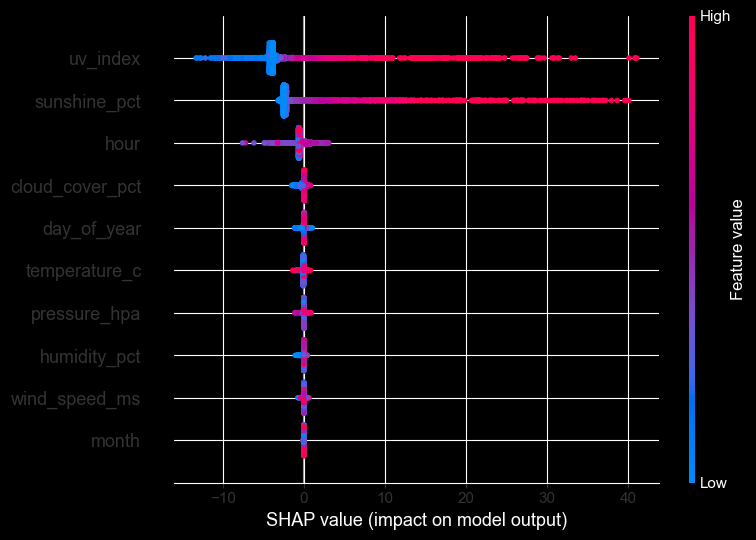

In [17]:
§import shap

explainer   = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)